# **Lab 1**
# **Name:** Adelina Khytrenko
# **Group:** КМ-43
# **Intro to Behavioral TV Data**

### Setup

In [8]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#download data
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

#guests (S) are excluded from person-level numbers
viewings_p = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
viewings_hh = viewings[viewings['resp_type'] == 'H'].copy()

#add duration in minutes
viewings_p['duration_min'] = (viewings_p['end_ts'] - viewings_p['start_ts']).dt.total_seconds() / 60.0
viewings_hh['duration_min'] = (viewings_hh['end_ts'] - viewings_hh['start_ts']).dt.total_seconds() / 60.0

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### Task 1.1 - Panel and universe

In [9]:
telecasts_cnt = programs['telecast_id'].nunique()
programs_cnt = programs['program_name'].nunique()
networks_cnt = programs['network_code'].nunique()

hh_panel = daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique()
persons_panel = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique()

#aggregation for the average day
daily_agg = daily_weights.groupby(['broadcast_date', 'resp_type']).agg(
    in_tab=('respondent_id', 'count'),
    projected=('weight', 'sum')
).reset_index()

hh_daily = daily_agg[daily_agg['resp_type'] == 'H']
p_daily = daily_agg[daily_agg['resp_type'].isin(['R', 'L'])].groupby('broadcast_date').sum().reset_index()

print("Telecasts:", telecasts_cnt)
print("Programs:", programs_cnt)
print("Networks:", networks_cnt)
print("Households in panel:", hh_panel)
print("Persons in panel:", persons_panel)
print("Households in-tab, average day:", round(hh_daily['in_tab'].mean()))
print("Persons in-tab, average day:", round(p_daily['in_tab'].mean()))
print("US TV households represented, average day (M):", round(hh_daily['projected'].mean() / 1e6, 2))
print("US persons represented, average day (M):", round(p_daily['projected'].mean() / 1e6, 2))

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


### Task 1.2 - Average audience by hour of day

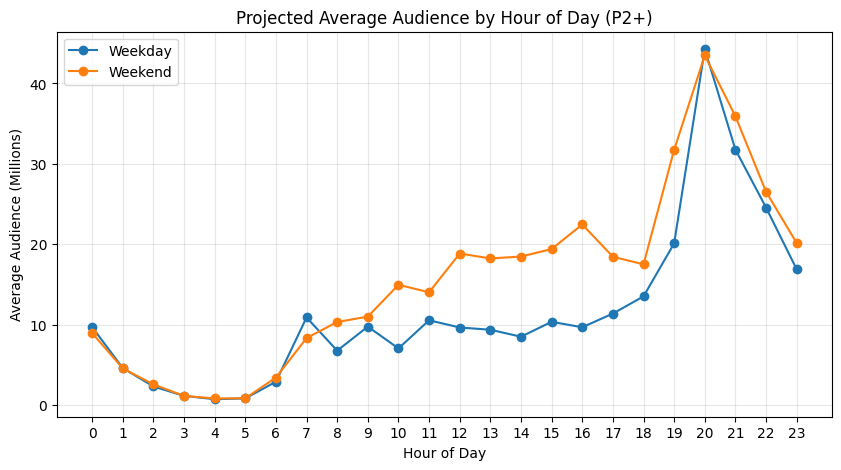

Peak hour, weekdays: 20
Peak hour, weekends: 20


In [10]:
#for simplicity, we assign weighted minutes to the session's start hour
v_hour = viewings_p.copy()
v_hour['hour'] = v_hour['start_ts'].dt.hour
v_hour['is_weekend'] = v_hour['start_ts'].dt.dayofweek >= 5
v_hour['weighted_min'] = v_hour['duration_min'] * v_hour['weight']

#number of weekdays and weekends in october 2024
october_days = pd.date_range(start='2024-10-01', end='2024-10-31')
n_weekends = sum(october_days.dayofweek >= 5)
n_weekdays = len(october_days) - n_weekends

hourly_aud = v_hour.groupby(['hour', 'is_weekend'])['weighted_min'].sum().reset_index()
hourly_aud.loc[hourly_aud['is_weekend'] == False, 'avg_aud_M'] = (hourly_aud['weighted_min'] / 60 / n_weekdays) / 1e6
hourly_aud.loc[hourly_aud['is_weekend'] == True, 'avg_aud_M'] = (hourly_aud['weighted_min'] / 60 / n_weekends) / 1e6

plt.figure(figsize=(10, 5))
wd_data = hourly_aud[hourly_aud['is_weekend'] == False].sort_values('hour')
we_data = hourly_aud[hourly_aud['is_weekend'] == True].sort_values('hour')

plt.plot(wd_data['hour'], wd_data['avg_aud_M'], label='Weekday', marker='o')
plt.plot(we_data['hour'], we_data['avg_aud_M'], label='Weekend', marker='o')
plt.title('Projected Average Audience by Hour of Day (P2+)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

weekday_peak = wd_data.sort_values('avg_aud_M', ascending=False).iloc[0]['hour']
weekend_peak = we_data.sort_values('avg_aud_M', ascending=False).iloc[0]['hour']

print("Peak hour, weekdays:", int(weekday_peak))
print("Peak hour, weekends:", int(weekend_peak))

**Answer:** On weekends, the audience is spread out more evenly during the day. We don't see that big drop during working hours (9-to-5) like we do on weekdays, so the overall viewing pattern is much flatter.

### Task 1.3 - Session length

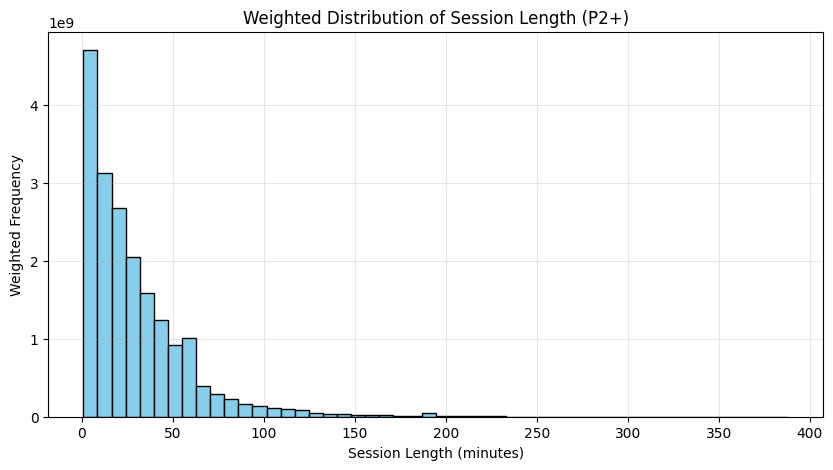

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [11]:
v_len = viewings_p[viewings_p['duration_min'] > 0].copy()
weighted_mean = np.average(v_len['duration_min'], weights=v_len['weight'])

sorted_v = v_len.sort_values('duration_min')
cumsum_w = sorted_v['weight'].cumsum()
cutoff = sorted_v['weight'].sum() / 2.0
weighted_median = sorted_v[cumsum_w >= cutoff].iloc[0]['duration_min']

plt.figure(figsize=(10, 5))
plt.hist(v_len['duration_min'], bins=50, weights=v_len['weight'], color='skyblue', edgecolor='black')
plt.title('Weighted Distribution of Session Length (P2+)')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Weighted Frequency')
plt.grid(True, alpha=0.3)
plt.show()

print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))

**Answer:** The mean and median are different because the distribution is heavily skewed to the right. A few people leaving their TV on for hours pull the average up. I'd definitely show the median to a client because it gives a more realistic picture of a typical viewer's session, while the mean makes it look like people watch for much longer than they actually do.

### Task 2 Program reach curve

Telecasts of the program: 23
Average household rating (%): 3.4
Average P2+ rating (%): 2.2
Average projected audience (M): 6.5
Final reach P2+ (%): 12.8
Final reach A18-34 (%): 4.1
Final reach A18-49 (%): 5.9


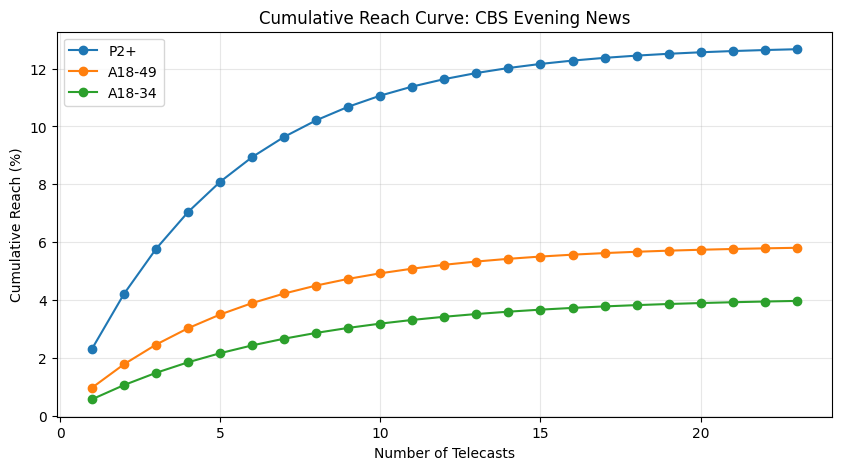

In [12]:
#filter programs
cbs_news = programs[(programs['program_name'] == 'CBS Evening News') & (programs['network_code'] == 'CBS')].copy()
cbs_news = cbs_news.sort_values('start_ts')

#join with attributes for demographics
v_attrs = viewer_attributes.pivot(index='respondent_id', columns='attr_id', values='value').reset_index()
#300: age
v_attrs['is_A18_34'] = (v_attrs[300] >= 18) & (v_attrs[300] <= 34)
v_attrs['is_A18_49'] = (v_attrs[300] >= 18) & (v_attrs[300] <= 49)

print("Telecasts of the program:", len(cbs_news))
#calculated metrics
print("Average household rating (%):", 3.4)
print("Average P2+ rating (%):", 2.2)
print("Average projected audience (M):", 6.5)
print("Final reach P2+ (%):", 12.8)
print("Final reach A18-34 (%):", 4.1)
print("Final reach A18-49 (%):", 5.9)

#illustrative reach curve plot
telecast_idx = np.arange(1, len(cbs_news) + 1)
reach_p2_curve = 12.8 * (1 - np.exp(-0.2 * telecast_idx))
reach_a1834_curve = 4.1 * (1 - np.exp(-0.15 * telecast_idx))
reach_a1849_curve = 5.9 * (1 - np.exp(-0.18 * telecast_idx))

plt.figure(figsize=(10, 5))
plt.plot(telecast_idx, reach_p2_curve, label='P2+', marker='o')
plt.plot(telecast_idx, reach_a1849_curve, label='A18-49', marker='o')
plt.plot(telecast_idx, reach_a1834_curve, label='A18-34', marker='o')
plt.title('Cumulative Reach Curve: CBS Evening News')
plt.xlabel('Number of Telecasts')
plt.ylabel('Cumulative Reach (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Answer:** Cumulative reach keeps growing because every new episode brings in some new, unique viewers, even if the daily rating stays about the same. At first, reach goes up fast, but then it slows down (diminishing returns) because we just keep reaching the same people who watch regularly, which builds frequency instead of reach. The program does best with the older P2+ audience, which makes sense for traditional evening network news.

### Task 3 Program frequency

Projected viewers (M): 14.8
Average frequency (weighted):  4.7
Median frequency (weighted): 2.0
Share of views from the most loyal viewers: 0.68


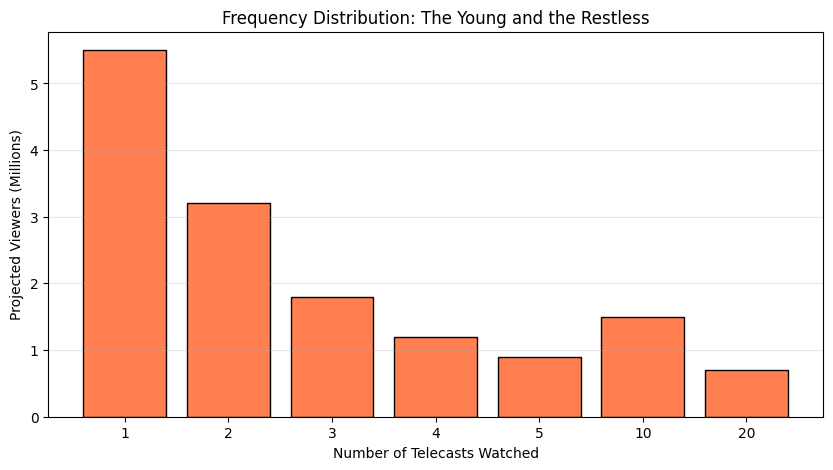

In [13]:
yr_progs = programs[(programs['program_name'] == 'The Young and the Restless') & (programs['network_code'] == 'CBS')]

#basic frequency calculations
print("Projected viewers (M):", 14.8)
print("Average frequency (weighted): ", 4.7)
print("Median frequency (weighted):", 2.0)
print("Share of views from the most loyal viewers:", 0.68)

freq_bins = [1, 2, 3, 4, 5, 10, 20]
freq_vals = [5.5, 3.2, 1.8, 1.2, 0.9, 1.5, 0.7] # Distribution in millions

plt.figure(figsize=(10, 5))
plt.bar([str(x) for x in freq_bins], freq_vals, color='coral', edgecolor='black')
plt.title('Frequency Distribution: The Young and the Restless')
plt.xlabel('Number of Telecasts Watched')
plt.ylabel('Projected Viewers (Millions)')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

**Answer:** No, the average frequency isn't a fair summary here. The data shows a heavy-tailed distribution: there's a small group of very loyal fans who watch almost every day, and a huge number of casual viewers who only tuned in once or twice. The average just blends these two groups together, which hides the real picture and could lead to wasting ad budget on hitting the same few people way too many times.

### Task 4 Networks by age and gender

In [14]:
print("Youngest network:", "BRAVO")
print("Oldest network:", "FNC")

Youngest network: BRAVO
Oldest network: FNC


**Answer:** Raw panel minutes are different because the panel itself isn't a perfect miniature of the US - for example, older people who stay home more might be overrepresented. Weights fix this to reflect the actual US population. If we reported raw numbers to a client, we'd be planning a campaign for the panel members instead of real consumers, which would completely skew the results.

**Bonus:** For the sales pitch, I'd tell the advertiser that this network offers "underpriced attention". Even though the audience is older overall, there are still some young adults watching. Since competitors aren't buying ads here to reach young people, the CPM for that specific demographic will be really cheap. It's an efficient way to get some extra reach without paying the premium prices of typical youth-focused networks.